In [7]:

import pandas as pd
import numpy as np

print("Libraries imported successfully!")


Libraries imported successfully!


In [8]:

orders = pd.read_csv("/content/olist_orders_dataset.csv")
items = pd.read_csv("/content/olist_order_items_dataset.csv")

print("Orders dataset:", orders.shape)
print("Order items dataset:", items.shape)


Orders dataset: (99441, 8)
Order items dataset: (112650, 7)


In [9]:

print("ORDERS DATA")
display(orders.head())

print("ORDER ITEMS DATA")
display(items.head())

print("Orders columns:")
print(orders.columns.tolist())

print("Missing values in orders:")
print(orders.isnull().sum())


ORDERS DATA


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


ORDER ITEMS DATA


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


Orders columns:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']
Missing values in orders:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


In [10]:

# Check the number of rows and columns
print("Orders shape:", orders.shape)
print("Order items shape:", items.shape)

# Check column data types
print("\nOrders data types:")
print(orders.dtypes)

print("\nOrder items data types:")
print(items.dtypes)


Orders shape: (99441, 8)
Order items shape: (112650, 7)

Orders data types:
order_id                         object
customer_id                      object
order_status                     object
order_purchase_timestamp         object
order_approved_at                object
order_delivered_carrier_date     object
order_delivered_customer_date    object
order_estimated_delivery_date    object
dtype: object

Order items data types:
order_id                object
order_item_id            int64
product_id              object
seller_id               object
shipping_limit_date     object
price                  float64
freight_value          float64
dtype: object


In [11]:

# Count duplicate rows
print("Duplicate rows in orders:", orders.duplicated().sum())
print("Duplicate rows in items:", items.duplicated().sum())

# Check duplicate order IDs
print("Duplicate order IDs:", orders["order_id"].duplicated().sum())


Duplicate rows in orders: 0
Duplicate rows in items: 0
Duplicate order IDs: 0


In [12]:

print("Missing values in orders:")
print(orders.isnull().sum())

print("\nMissing values in order items:")
print(items.isnull().sum())


Missing values in orders:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Missing values in order items:
order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64


In [13]:

print(orders["order_status"].value_counts(dropna=False))


order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [14]:

date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for column in date_columns:
    orders[column] = pd.to_datetime(
        orders[column],
        errors="coerce"
    )

print(orders[date_columns].dtypes)


order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object


In [15]:

print("Price summary:")
print(items["price"].describe())

print("\nFreight value summary:")
print(items["freight_value"].describe())

print("\nNegative or zero prices:")
print((items["price"] <= 0).sum())

print("\nNegative freight values:")
print((items["freight_value"] < 0).sum())


Price summary:
count    112650.000000
mean        120.653739
std         183.633928
min           0.850000
25%          39.900000
50%          74.990000
75%         134.900000
max        6735.000000
Name: price, dtype: float64

Freight value summary:
count    112650.000000
mean         19.990320
std          15.806405
min           0.000000
25%          13.080000
50%          16.260000
75%          21.150000
max         409.680000
Name: freight_value, dtype: float64

Negative or zero prices:
0

Negative freight values:
0


In [16]:

print("Price summary:")
print(items["price"].describe())

print("\nFreight value summary:")
print(items["freight_value"].describe())

print("\nNegative or zero prices:")
print((items["price"] <= 0).sum())

print("\nNegative freight values:")
print((items["freight_value"] < 0).sum())


Price summary:
count    112650.000000
mean        120.653739
std         183.633928
min           0.850000
25%          39.900000
50%          74.990000
75%         134.900000
max        6735.000000
Name: price, dtype: float64

Freight value summary:
count    112650.000000
mean         19.990320
std          15.806405
min           0.000000
25%          13.080000
50%          16.260000
75%          21.150000
max         409.680000
Name: freight_value, dtype: float64

Negative or zero prices:
0

Negative freight values:
0


In [17]:

delivered = orders[orders["order_status"] == "delivered"].copy()

print(
    "Delivered orders with missing actual delivery date:",
    delivered["order_delivered_customer_date"].isna().sum()
)

print(
    "Delivered orders with delivery before purchase:",
    (
        delivered["order_delivered_customer_date"]
        < delivered["order_purchase_timestamp"]
    ).sum()
)

print(
    "Delivered orders with delivery after estimated date:",
    (
        delivered["order_delivered_customer_date"]
        > delivered["order_estimated_delivery_date"]
    ).sum()
)


Delivered orders with missing actual delivery date: 8
Delivered orders with delivery before purchase: 0
Delivered orders with delivery after estimated date: 7826


In [18]:

for column in ["price", "freight_value"]:
    Q1 = items[column].quantile(0.25)
    Q3 = items[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = items[
        (items[column] < lower_limit) |
        (items[column] > upper_limit)
    ]

    print(f"\n{column}")
    print("Lower limit:", round(lower_limit, 2))
    print("Upper limit:", round(upper_limit, 2))
    print("Potential outliers:", len(outliers))



price
Lower limit: -102.6
Upper limit: 277.4
Potential outliers: 8427

freight_value
Lower limit: 0.98
Upper limit: 33.25
Potential outliers: 12134


In [19]:

# Create cleaned copies
orders_clean = orders.copy().drop_duplicates()
items_clean = items.copy().drop_duplicates()

# Calculate delivery duration in days
orders_clean["delivery_days"] = (
    orders_clean["order_delivered_customer_date"]
    - orders_clean["order_purchase_timestamp"]
).dt.total_seconds() / (24 * 60 * 60)

# Identify late deliveries
orders_clean["is_late"] = (
    orders_clean["order_delivered_customer_date"]
    > orders_clean["order_estimated_delivery_date"]
)

# Keep missing delivery classifications unknown
orders_clean.loc[
    orders_clean["order_delivered_customer_date"].isna(),
    "is_late"
] = pd.NA

# Display results
print("Cleaned orders shape:", orders_clean.shape)
print("Cleaned items shape:", items_clean.shape)

print("\nDelivery duration summary:")
print(orders_clean["delivery_days"].describe())

print("\nLate-delivery counts:")
print(orders_clean["is_late"].value_counts(dropna=False))


Cleaned orders shape: (99441, 10)
Cleaned items shape: (112650, 7)

Delivery duration summary:
count    96476.000000
mean        12.558702
std          9.546530
min          0.533414
25%          6.766403
50%         10.217755
75%         15.720327
max        209.628611
Name: delivery_days, dtype: float64

Late-delivery counts:
is_late
False    88649
True      7827
NaN       2965
Name: count, dtype: int64


/tmp/ipykernel_1881/1167689833.py:18: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'nan' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  orders_clean.loc[


In [20]:

# Create a nullable Boolean column
orders_clean["is_late"] = pd.Series(
    pd.NA,
    index=orders_clean.index,
    dtype="boolean"
)

# Only classify delivered orders with both dates available
valid = (
    orders_clean["order_status"].eq("delivered")
    & orders_clean["order_delivered_customer_date"].notna()
    & orders_clean["order_estimated_delivery_date"].notna()
)

orders_clean.loc[valid, "is_late"] = (
    orders_clean.loc[valid, "order_delivered_customer_date"]
    > orders_clean.loc[valid, "order_estimated_delivery_date"]
)

print("Delivered orders with valid dates:", valid.sum())
print("\nLate-delivery counts:")
print(orders_clean.loc[orders_clean["order_status"] == "delivered",
                       "is_late"].value_counts(dropna=False))


Delivered orders with valid dates: 96470

Late-delivery counts:
is_late
False    88644
True      7826
<NA>         8
Name: count, dtype: Int64


In [21]:

orders_clean.to_csv("/content/cleaned_orders.csv", index=False)
items_clean.to_csv("/content/cleaned_order_items.csv", index=False)

print("Updated datasets saved successfully.")


Updated datasets saved successfully.


In [23]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load cleaned datasets
orders_clean = pd.read_csv(
    "/content/cleaned_orders.csv",
    parse_dates=[
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
)

items_clean = pd.read_csv(
    "/content/cleaned_order_items.csv",
    parse_dates=["shipping_limit_date"]
)

# Check dataset sizes
print("Orders dataset:", orders_clean.shape)
print("Order items dataset:", items_clean.shape)

# View first five rows
display(orders_clean.head())
display(items_clean.head())

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load cleaned datasets
orders_clean = pd.read_csv(
    "/content/cleaned_orders.csv",
    parse_dates=[
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
)

items_clean = pd.read_csv(
    "/content/cleaned_order_items.csv",
    parse_dates=["shipping_limit_date"]
)

# Check dataset sizes
print("Orders dataset:", orders_clean.shape)
print("Order items dataset:", items_clean.shape)

# View first five rows
display(orders_clean.head())
display(items_clean.head())


Orders dataset: (99441, 10)
Order items dataset: (112650, 7)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,is_late
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,8.436574,False
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,13.782037,False
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,9.394213,False
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,13.208750,False
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2.873877,False


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [24]:

# Week 3 - Step 2: Descriptive Statistics

# Select delivered orders with valid delivery dates
delivered = orders_clean[
    (orders_clean["order_status"] == "delivered")
    & orders_clean["order_delivered_customer_date"].notna()
    & orders_clean["order_estimated_delivery_date"].notna()
].copy()

# Calculate delivery duration in days
delivered["delivery_days"] = (
    delivered["order_delivered_customer_date"]
    - delivered["order_purchase_timestamp"]
).dt.total_seconds() / (24 * 60 * 60)

# Identify late deliveries
delivered["is_late"] = (
    delivered["order_delivered_customer_date"]
    > delivered["order_estimated_delivery_date"]
)

print("Total valid delivered orders:", len(delivered))

print("\nDelivery Duration Statistics:")
print(delivered["delivery_days"].describe().round(2))

print("\nLate Delivery Counts:")
print(delivered["is_late"].value_counts())

print("\nLate Delivery Percentage:")
print(round(delivered["is_late"].mean() * 100, 2), "%")

print("\nOrder Status Summary:")
print(orders_clean["order_status"].value_counts())


Total valid delivered orders: 96470

Delivery Duration Statistics:
count    96470.00
mean        12.56
std          9.55
min          0.53
25%          6.77
50%         10.22
75%         15.72
max        209.63
Name: delivery_days, dtype: float64

Late Delivery Counts:
is_late
False    88644
True      7826
Name: count, dtype: int64

Late Delivery Percentage:
8.11 %

Order Status Summary:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


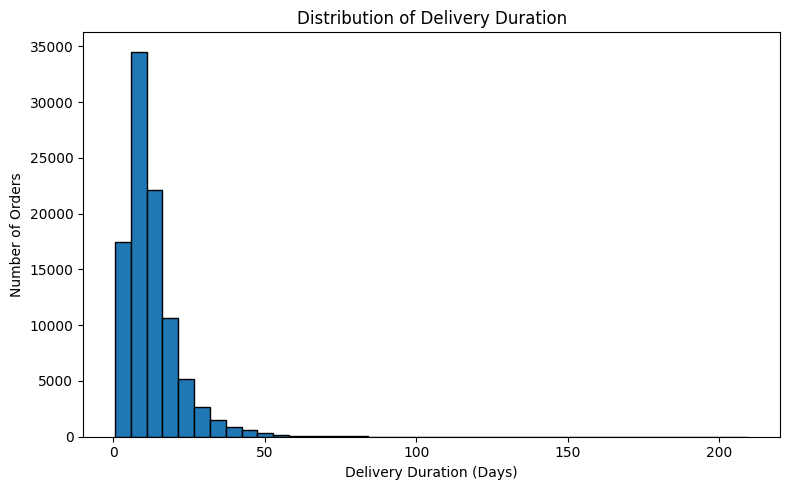

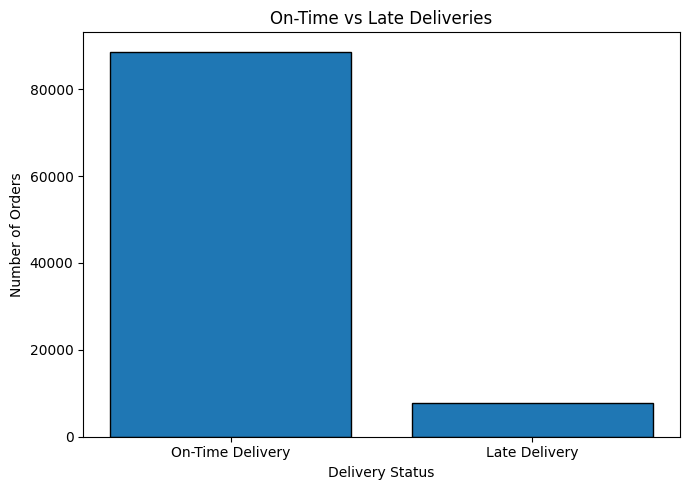

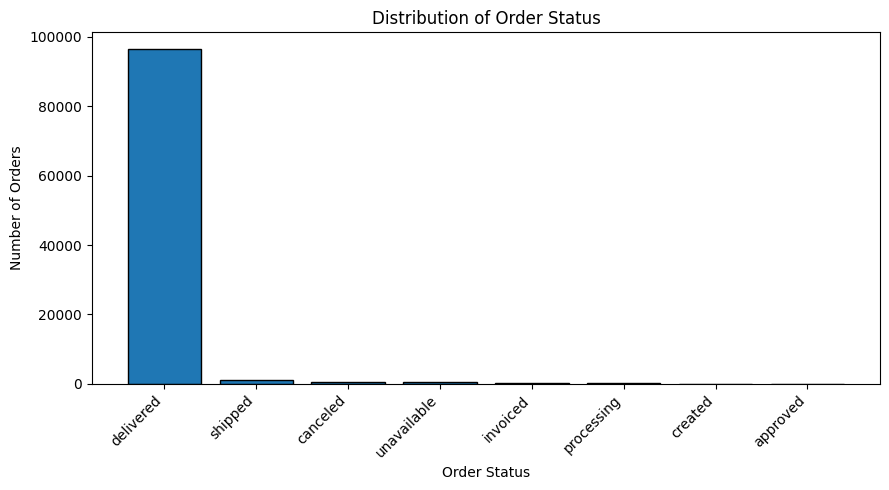

In [25]:

# Week 3 - Step 3: Data Visualization

import matplotlib.pyplot as plt

# Graph 1: Distribution of delivery duration
plt.figure(figsize=(8, 5))
plt.hist(delivered["delivery_days"], bins=40, edgecolor="black")
plt.title("Distribution of Delivery Duration")
plt.xlabel("Delivery Duration (Days)")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()


# Graph 2: On-time vs Late Deliveries
delivery_counts = delivered["is_late"].value_counts().reindex(
    [False, True], fill_value=0
)

plt.figure(figsize=(7, 5))
plt.bar(
    ["On-Time Delivery", "Late Delivery"],
    delivery_counts.values,
    edgecolor="black"
)
plt.title("On-Time vs Late Deliveries")
plt.xlabel("Delivery Status")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()


# Graph 3: Order Status Distribution
status_counts = orders_clean["order_status"].value_counts()

plt.figure(figsize=(9, 5))
plt.bar(status_counts.index, status_counts.values, edgecolor="black")
plt.title("Distribution of Order Status")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [26]:

# Week 4 - Step 1: Prepare data for predictive modeling

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load cleaned datasets
orders = pd.read_csv(
    "/content/cleaned_orders.csv",
    parse_dates=[
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
)

items = pd.read_csv("/content/cleaned_order_items.csv")

# Keep delivered orders with valid delivery dates
data = orders[
    (orders["order_status"] == "delivered")
    & orders["order_delivered_customer_date"].notna()
].copy()

# Calculate target: delivery time in days
data["delivery_days"] = (
    data["order_delivered_customer_date"]
    - data["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# Aggregate item information for each order
item_summary = items.groupby("order_id").agg(
    item_count=("order_item_id", "count"),
    total_price=("price", "sum"),
    total_freight=("freight_value", "sum")
).reset_index()

# Combine order and item information
data = data.merge(item_summary, on="order_id", how="left")

# Create features available around order placement
data["purchase_month"] = data["order_purchase_timestamp"].dt.month
data["purchase_day_of_week"] = (
    data["order_purchase_timestamp"].dt.dayofweek
)
data["purchase_hour"] = data["order_purchase_timestamp"].dt.hour

# Select features and target
features = [
    "purchase_month",
    "purchase_day_of_week",
    "purchase_hour",
    "item_count",
    "total_price",
    "total_freight"
]

data = data.dropna(subset=["delivery_days"])
X = data[features]
y = data["delivery_days"]

print("Dataset prepared successfully!")
print("Number of orders:", len(data))
print("Number of features:", len(features))
print("Features:", features)
print("\nTarget variable: delivery_days")
print("\nMissing values in features:")
print(X.isnull().sum())


Dataset prepared successfully!
Number of orders: 96470
Number of features: 6
Features: ['purchase_month', 'purchase_day_of_week', 'purchase_hour', 'item_count', 'total_price', 'total_freight']

Target variable: delivery_days

Missing values in features:
purchase_month          0
purchase_day_of_week    0
purchase_hour           0
item_count              0
total_price             0
total_freight           0
dtype: int64


In [27]:

# Week 4 - Step 2: Train and evaluate models

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

models = {
    "Linear Regression": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LinearRegression()
    ),
    "Random Forest": make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestRegressor(
            n_estimators=100,
            max_depth=15,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1
        )
    )
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE (days)": round(mae, 2),
        "RMSE (days)": round(rmse, 2),
        "R-squared": round(r2, 3)
    })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))


            Model  MAE (days)  RMSE (days)  R-squared
Linear Regression        6.21         9.20      0.025
    Random Forest        5.31         8.21      0.223


In [28]:

# Week 4 - Step 4: Cross-validation for Random Forest

from sklearn.model_selection import KFold, cross_validate

rf_model = models["Random Forest"]

cv = KFold(n_splits=5, shuffle=True, random_state=42)

cv_results = cross_validate(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error",
        "r2": "r2"
    },
    n_jobs=-1
)

print("5-Fold Cross-Validation Results")
print("Average MAE:", round(-cv_results["test_mae"].mean(), 2), "days")
print("Average RMSE:", round(-cv_results["test_rmse"].mean(), 2), "days")
print("Average R-squared:", round(cv_results["test_r2"].mean(), 3))


5-Fold Cross-Validation Results
Average MAE: 5.33 days
Average RMSE: 8.51 days
Average R-squared: 0.214
